# 06 · Representation data: who enrolled in U.S.-only trials

**Focused component (Role Y), part 1 of 2.** This notebook builds one row per trial with the enrolled
sex, race, ethnicity and age mix, for trials where **every site is in the U.S.** Notebook `08_census_linking`
compares these shares with the Census population of the counties around each trial's sites.

**Why U.S.-only:** AACT posts enrolled demographics for the whole trial, not per country, so a multi-country
trial cannot be fairly compared with one country's Census population.

**Inputs** (`data/raw/`, from `scripts/02_extract.py` and `scripts/04_extract_representation.py`):
`countries`, `facilities_geo`, `baseline_demographics`, `result_groups_baseline`, plus `data/processed/trials.parquet` (from `03_build_dataset.py`).

**Outputs** (`data/processed/`, git-ignored):
- `representation_trials.parquet`: one row per U.S.-only trial with posted demographics
- `us_sites.parquet`: one row per site of those trials (ZIP, lat/long), used by notebook 08
- figures in `notebooks/figures/rep_*.png`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Analysis settings
RACE_UNKNOWN_MAX = 0.50   # drop race shares when more than half of participants have unknown race
MIN_ENROLLED = 10         # drop trials with fewer participants than this (shares too noisy)

## 1. Load

In [2]:
trials = pd.read_parquet(PROC / "trials.parquet")
trials = trials.drop(columns=[c for c in ["criteria"] if c in trials.columns])
countries = pd.read_parquet(RAW / "countries.parquet")
fac = pd.read_parquet(RAW / "facilities_geo.parquet")
bm = pd.read_parquet(RAW / "baseline_demographics.parquet")
rg = pd.read_parquet(RAW / "result_groups_baseline.parquet")

for name, df in [("trials", trials), ("countries", countries), ("facilities_geo", fac),
                 ("baseline_demographics", bm), ("result_groups_baseline", rg)]:
    print(f"{name:<22} {len(df):>10,} rows  {df['nct_id'].nunique():>8,} trials")

trials                    231,810 rows   231,810 trials
countries                 352,604 rows   215,865 trials
facilities_geo          1,658,335 rows   212,959 trials
baseline_demographics   1,197,380 rows    54,197 trials
result_groups_baseline    169,398 rows    54,977 trials


## 2. U.S.-only trials

A trial counts as U.S.-only when (a) its only listed country is the United States (ignoring countries
marked `removed`), and (b) every facility it lists is in the United States. Both must hold, because the two
tables occasionally disagree.

In [3]:
US = "United States"

ctry = countries.copy()
if "removed" in ctry.columns:
    ctry = ctry[ctry["removed"].fillna(False).astype(bool) == False]  # noqa: E712
ctry_ok = ctry.assign(is_us=ctry["name"].eq(US)).groupby("nct_id")["is_us"].all()

fac_ok = fac.assign(is_us=fac["country"].eq(US)).groupby("nct_id")["is_us"].all()

us_only = set(ctry_ok[ctry_ok].index) & set(fac_ok[fac_ok].index)
print(f"Trials with any country listed:     {ctry_ok.size:>8,}")
print(f"U.S.-only by countries table:       {ctry_ok.sum():>8,}")
print(f"U.S.-only by facilities table:      {fac_ok.sum():>8,}")
print(f"U.S.-only by both (used):           {len(us_only):>8,}")

Trials with any country listed:      212,959
U.S.-only by countries table:         73,731
U.S.-only by facilities table:        73,731
U.S.-only by both (used):             73,731


## 3. Enrolled demographics from posted results

`baseline_measurements` has one row per (trial, arm, category). Most trials also post a **Total** column,
which we use. When a trial has no Total column, we sum across its arms. Only the standard NIH/OMB measures
are used; free-text "Customized" measures are left out because their categories are inconsistent.

In [4]:
# Which baseline group is the trial total?
rg = rg.assign(is_total=rg["title"].fillna("").str.strip().str.lower().eq("total"))
has_total = rg.groupby("nct_id")["is_total"].any().rename("has_total")

d = bm[bm["nct_id"].isin(us_only)].copy()
d = d.merge(rg[["id", "is_total"]].rename(columns={"id": "result_group_id"}), on="result_group_id", how="left")
d = d.merge(has_total, on="nct_id", how="left")
d["is_total"] = d["is_total"].fillna(False).astype(bool)
d["has_total"] = d["has_total"].fillna(False).astype(bool)
# keep the Total group if the trial has one, otherwise keep every arm (summed below)
d = d[d["is_total"] | ~d["has_total"]]

not_collected = set(d.loc[d["title"].eq("Race and Ethnicity Not Collected"), "nct_id"])
d = d[d["param_type"].str.upper().eq("COUNT_OF_PARTICIPANTS")]

MEASURE = {"Sex: Female, Male": "sex", "Gender": "sex", "Race (NIH/OMB)": "race",
           "Ethnicity (NIH/OMB)": "eth", "Age, Categorical": "age"}
CATEGORY = {
    "sex": {"female": "female", "male": "male"},
    "race": {"white": "white", "black or african american": "black", "asian": "asian",
             "american indian or alaska native": "aian",
             "native hawaiian or other pacific islander": "nhpi",
             "more than one race": "multi", "unknown or not reported": "unknown"},
    "eth": {"hispanic or latino": "hispanic", "not hispanic or latino": "not_hispanic",
            "unknown or not reported": "unknown"},
    "age": {"<=18 years": "under18", "between 18 and 65 years": "18_64", ">=65 years": "65plus"},
}

d["measure"] = d["title"].map(MEASURE)
d = d[d["measure"].notna()]
cat_text = d["category"].fillna(d["classification"]).fillna("").str.strip().str.lower()
d["cat"] = [CATEGORY[m].get(c) for m, c in zip(d["measure"], cat_text)]

unmapped = d.loc[d["cat"].isna()].assign(cat_text=cat_text[d["cat"].isna()])
print("Unmapped categories (should be empty or tiny):")
print(unmapped.groupby(["measure", "cat_text"]).size().sort_values(ascending=False).head(10).to_string())

d = d[d["cat"].notna()]
counts = (d.groupby(["nct_id", "measure", "cat"])["param_value_num"].sum()
            .unstack(["measure", "cat"]))
counts.columns = [f"{m}_{c}_n" for m, c in counts.columns]
counts = counts.reset_index()
print(f"\nTrials with standard demographics: {len(counts):,}")
counts.head()

Unmapped categories (should be empty or tiny):
measure  cat_text                      
age      btwn                              5
         gte65                             5
         lte18                             5
eth      hispanic                          4
race     black                             4
         hawaiian                          4
         american indian/ alaska native    1

Trials with standard demographics: 31,258


,nct_id,sex_female_n,sex_male_n,age_18_64_n,age_65plus_n,age_under18_n,eth_hispanic_n,eth_not_hispanic_n,eth_unknown_n,race_aian_n,race_asian_n,race_black_n,race_multi_n,race_nhpi_n,race_unknown_n,race_white_n
0,NCT00124462,50.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NCT00125528,25.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NCT00125658,2.0,12.0,10.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NCT00130117,20.0,0.0,20.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NCT00147966,18.0,6.0,19.0,5.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Shares and quality checks

- **Race shares** use only participants with known race in the denominator; `race_unknown_pct` is kept,
  and race shares are blanked when more than `RACE_UNKNOWN_MAX` is unknown.
- **Hispanic share** likewise uses known ethnicity.
- **Age 65+ share** is among adults (18–64 plus 65+), since Census comparisons in notebook 08 use adults.
- Trials with fewer than `MIN_ENROLLED` participants are dropped.

In [5]:
def col(df, name):
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)

def ssum(df, names):
    return df[[n for n in names if n in df.columns]].sum(axis=1, min_count=1)

r = counts.copy()
RACES = ["white", "black", "asian", "aian", "nhpi", "multi"]

r["n_enrolled"] = ssum(r, ["sex_female_n", "sex_male_n"])
r["share_female"] = col(r, "sex_female_n") / r["n_enrolled"]

race_known = ssum(r, [f"race_{x}_n" for x in RACES])
race_all = race_known + col(r, "race_unknown_n").fillna(0)
r["race_unknown_pct"] = 1 - race_known / race_all
for x in RACES:
    r[f"share_{x}"] = col(r, f"race_{x}_n") / race_known
too_unknown = r["race_unknown_pct"] > RACE_UNKNOWN_MAX
r.loc[too_unknown, [f"share_{x}" for x in RACES]] = np.nan

eth_known = ssum(r, ["eth_hispanic_n", "eth_not_hispanic_n"])
r["eth_unknown_pct"] = 1 - eth_known / (eth_known + col(r, "eth_unknown_n").fillna(0))
r["share_hispanic"] = col(r, "eth_hispanic_n") / eth_known
r.loc[r["eth_unknown_pct"] > RACE_UNKNOWN_MAX, "share_hispanic"] = np.nan

adults = ssum(r, ["age_18_64_n", "age_65plus_n"])
r["share_65plus_adults"] = col(r, "age_65plus_n") / adults

r["race_not_collected"] = r["nct_id"].isin(not_collected)
r = r.replace([np.inf, -np.inf], np.nan)

# sanity: race total should be close to sex total
mismatch = (race_all / r["n_enrolled"] - 1).abs() > 0.05
print(f"Race total differs from sex total by >5%: {mismatch.sum():,} trials (kept, flagged)")
r["flag_total_mismatch"] = mismatch

before = len(r)
r = r[r["n_enrolled"].fillna(0) >= MIN_ENROLLED]
print(f"Dropped {before - len(r):,} trials with < {MIN_ENROLLED} participants or no sex counts")
print(f"Race shares blanked for {too_unknown.sum():,} trials with > {RACE_UNKNOWN_MAX:.0%} unknown race")

Race total differs from sex total by >5%: 86 trials (kept, flagged)
Dropped 4,299 trials with < 10 participants or no sex counts
Race shares blanked for 249 trials with > 50% unknown race


## 5. Add trial attributes and save

In [6]:
keep_cols = [c for c in [
    "nct_id", "overall_status", "label", "phase", "start_year", "lead_sponsor_class",
    "healthy_volunteers", "gender", "minimum_age", "maximum_age", "adult", "child", "older_adult",
    "criteria_n_chars", "number_of_arms", "allocation", "primary_purpose",
] if c in trials.columns]
rep = r.merge(trials[keep_cols], on="nct_id", how="left")
rep["completed"] = rep["overall_status"].eq("COMPLETED")

# Sites for notebook 08
sites = fac[fac["nct_id"].isin(rep["nct_id"])].copy()
sites["zip5"] = sites["zip"].astype("string").str.extract(r"(\d{5})", expand=False)
sites = sites[["nct_id", "status", "city", "state", "zip5", "latitude", "longitude"]]
rep = rep.merge(sites.groupby("nct_id").size().rename("n_us_sites"), on="nct_id", how="left")

rep.to_parquet(PROC / "representation_trials.parquet", index=False)
sites.to_parquet(PROC / "us_sites.parquet", index=False)
print(f"Saved {len(rep):,} trials -> data/processed/representation_trials.parquet")
print(f"Saved {len(sites):,} sites  -> data/processed/us_sites.parquet "
      f"({sites['zip5'].notna().mean():.1%} have a 5-digit ZIP)")

Saved 26,959 trials -> data/processed/representation_trials.parquet
Saved 208,469 sites  -> data/processed/us_sites.parquet (94.2% have a 5-digit ZIP)


## 6. Coverage summary

How many trials survive each step. This table goes in the report's Methods section.

,trials,pct_of_cohort
"Cohort (interventional, 2008-2020)",231810,100.0%
U.S.-only sites,73731,31.8%
U.S.-only with posted standard demographics,31258,13.5%
... with >= 10 participants (analysis set),26959,11.6%
... with race shares,13904,6.0%
... with Hispanic share,10952,4.7%
... completed (main comparison set),23374,10.1%


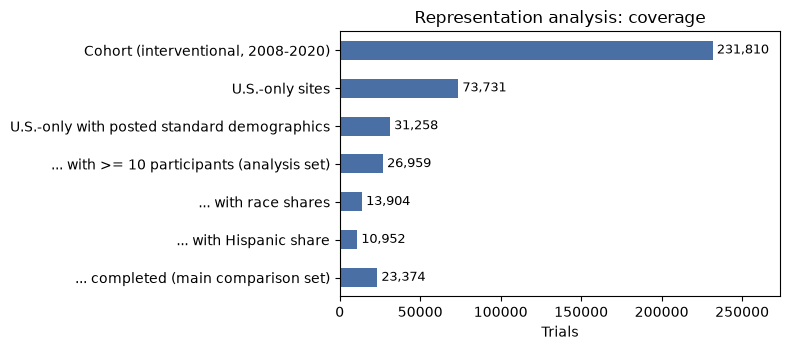

In [7]:
cohort = trials["nct_id"].nunique()
with_results = bm["nct_id"].nunique()
funnel = pd.Series({
    "Cohort (interventional, 2008-2020)": cohort,
    "U.S.-only sites": len(us_only),
    "U.S.-only with posted standard demographics": len(counts),
    f"... with >= {MIN_ENROLLED} participants (analysis set)": len(rep),
    "... with race shares": rep["share_white"].notna().sum(),
    "... with Hispanic share": rep["share_hispanic"].notna().sum(),
    "... completed (main comparison set)": rep["completed"].sum(),
}, name="trials")
display(funnel.to_frame().assign(pct_of_cohort=lambda t: (t["trials"] / cohort).map("{:.1%}".format)))

fig, ax = plt.subplots(figsize=(8, 3.6))
funnel[::-1].plot.barh(ax=ax, color="#4a6fa5")
for i, v in enumerate(funnel[::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_xlabel("Trials"); ax.set_title("Representation analysis: coverage")
ax.set_xlim(0, cohort * 1.18)
plt.tight_layout(); plt.savefig(FIG / "rep_coverage.png", dpi=200); plt.show()

## 7. Who enrolled

Distribution of each group's enrolled share across trials (completed trials, analysis set).
Notebook 08 compares these with the local population.

,trials,median share,pooled share,% trials with zero
Female,"23,374",50.0%,52.4%,4.3%
White,"11,839",80.8%,75.7%,1.6%
Black,"11,838",11.1%,17.2%,14.8%
Asian,"11,839",1.2%,3.8%,42.1%
Hispanic,"9,293",8.0%,15.4%,15.5%
Age 65+ (adults),"7,783",8.7%,25.9%,39.9%


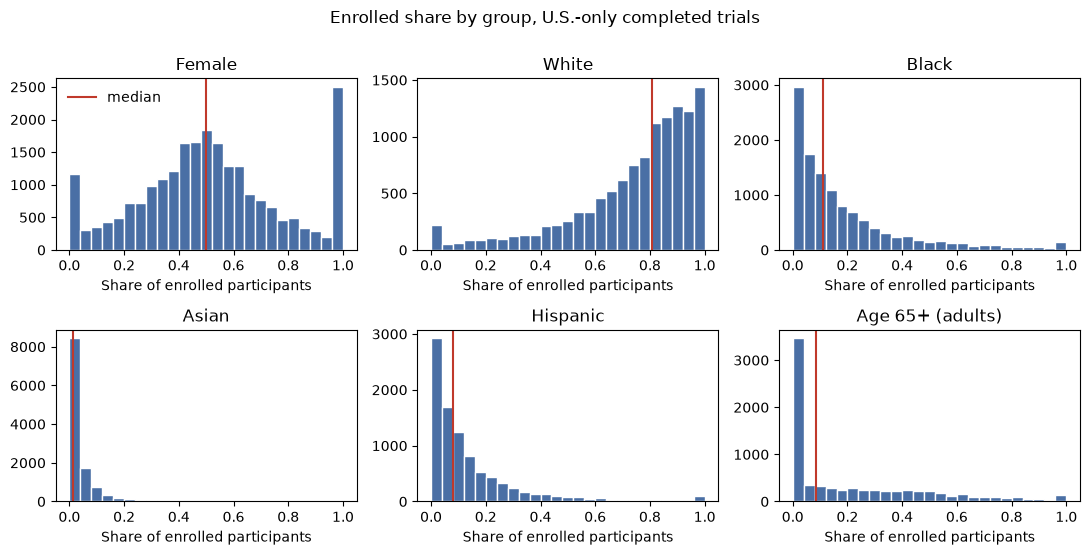

In [8]:
GROUPS = {"share_female": "Female", "share_white": "White", "share_black": "Black",
          "share_asian": "Asian", "share_hispanic": "Hispanic", "share_65plus_adults": "Age 65+ (adults)"}
comp = rep[rep["completed"]]

summary = pd.DataFrame({
    "trials": comp[list(GROUPS)].notna().sum(),
    "median share": comp[list(GROUPS)].median(),
    "pooled share": [  # participants pooled across trials
        comp["sex_female_n"].sum() / comp["n_enrolled"].sum(),
        *[comp[f"race_{x}_n"].sum() / comp[[f"race_{y}_n" for y in RACES]].sum().sum()
          for x in ["white", "black", "asian"]],
        comp["eth_hispanic_n"].sum() / comp[["eth_hispanic_n", "eth_not_hispanic_n"]].sum().sum(),
        comp["age_65plus_n"].sum() / comp[["age_18_64_n", "age_65plus_n"]].sum().sum(),
    ],
    "% trials with zero": (comp[list(GROUPS)] == 0).sum() / comp[list(GROUPS)].notna().sum(),
}).rename(index=GROUPS)
display(summary.style.format({"trials": "{:,.0f}", "median share": "{:.1%}",
                              "pooled share": "{:.1%}", "% trials with zero": "{:.1%}"}))

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharey=False)
for ax, (c, lab) in zip(axes.flat, GROUPS.items()):
    ax.hist(comp[c].dropna(), bins=np.linspace(0, 1, 26), color="#4a6fa5", edgecolor="white")
    ax.axvline(comp[c].median(), color="#c0392b", lw=1.5, label="median")
    ax.set_title(lab); ax.set_xlabel("Share of enrolled participants")
axes.flat[0].legend(frameon=False)
fig.suptitle("Enrolled share by group, U.S.-only completed trials", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "rep_enrolled_shares.png", dpi=200, bbox_inches="tight"); plt.show()

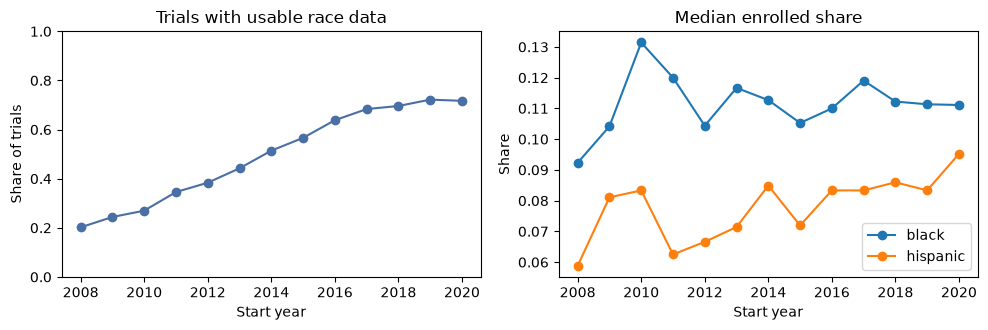

,trials,reports_race,black,hispanic
start_year,,,,
2008,1653,0.202057,0.092330,0.058824
2009,1749,0.244140,0.104167,0.081081
2010,1671,0.269898,0.131429,0.083333
2011,1594,0.345671,0.120000,0.062500
2012,1574,0.383736,0.104356,0.066611
2013,1750,0.442286,0.116667,0.071429
2014,1789,0.514254,0.112698,0.084906
2015,1863,0.566291,0.105263,0.071942
2016,1893,0.638141,0.109991,0.083333


In [9]:
# Reporting over time: share of trials reporting race at all, and pooled Black / Hispanic share
by_year = rep[rep["completed"]].groupby("start_year").agg(
    trials=("nct_id", "size"),
    reports_race=("share_white", lambda s: s.notna().mean()),
    black=("share_black", "median"),
    hispanic=("share_hispanic", "median"),
)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
by_year["reports_race"].plot(ax=ax[0], marker="o", color="#4a6fa5")
ax[0].set_ylim(0, 1); ax[0].set_title("Trials with usable race data"); ax[0].set_ylabel("Share of trials")
by_year[["black", "hispanic"]].plot(ax=ax[1], marker="o")
ax[1].set_title("Median enrolled share"); ax[1].set_ylabel("Share")
for a in ax: a.set_xlabel("Start year")
plt.tight_layout(); plt.savefig(FIG / "rep_trends.png", dpi=200); plt.show()
by_year

## Notes for the report

- Demographics come from posted results, so this set is **trials that reached results posting**, mostly
  completed trials. It is a different population from the termination model in notebook 05.
- Race uses the NIH/OMB categories; Hispanic ethnicity is a separate question, as in the Census.
- Trials posting only "Customized" race or sex measures are excluded (free text with inconsistent categories).
- `race_unknown_pct` and `flag_total_mismatch` are kept so later steps can test sensitivity to data quality.